# Machine output: budgeted interaction search

A calibrated input can have a different association with output in two operating
modes. This simulation uses `auto_policy` to discover that difference, inspect
its adoption decisions and predict new observations. It introduces a whole-search
fit budget and combined tree and neural preliminary exploration.

Each row is one independent machine run. The response `y` is measured in output
units; `x` is a dimensionless calibrated input and `mode` is recorded as 0 or 1
before the output is observed. Both predictors are eligible at prediction time.
The known conditional mean is $8(2\,\mathrm{mode}-1)x$, and independent Gaussian
noise has standard deviation 0.2 output units. The search receives only the two
predictors and the noisy response. There are no irrelevant predictors in this
introductory example, so it tests interaction recovery rather than noise-variable
selection.

:::{admonition} Study design
:class: dropdown
The target and estimand are mean squared prediction error for a new independent
run from this generating process, in output units squared. We generate 180
training rows and an independent 400-row test sample. Three random training
folds select specifications and stopping iterations. Test responses are used
only after the models are fixed. The claim is methodological and predictive.
Test standard errors describe variation among the 400 test losses conditional
on these fitted models; they omit uncertainty from repeating the training search.
:::

## Training and test samples

Polars keeps predictor names attached to the generated values. Separate random
seeds make the evaluation sample independent of training.

In [1]:
import altair as alt
import numpy as np
import polars as pl
from IPython.display import display

import mboostrs as mb
from bench_tables import table

alt.renderers.enable("svg")

rng = np.random.default_rng(41)
x = rng.uniform(-1, 1, 180)
mode = rng.integers(0, 2, 180)
train = pl.DataFrame({"x": x, "mode": mode,
                      "y": 8 * (2 * mode - 1) * x + rng.normal(0, .2, 180)})

In [2]:
test_rng = np.random.default_rng(42)
test_x = test_rng.uniform(-1, 1, 400)
test_mode = test_rng.integers(0, 2, 400)
test_mean = 8 * (2 * test_mode - 1) * test_x
test = pl.DataFrame({"x": test_x, "mode": test_mode,
                     "y": test_mean + test_rng.normal(0, .2, 400)})
display(train.head())

x,mode,y
f64,i64,f64
0.908302,0,-7.509037
0.535864,1,4.451974
-0.748059,0,5.830619
0.653976,0,-5.54194
0.698144,0,-5.334394


## Linear baseline

`tune_mstop` fits the stated specification and chooses its stopping iteration
by cross-validation. `Gaussian()` specifies squared-error fitting, `score="mse"`
selects by mean squared error, and `start=100` starts a grid that can extend
if its minimum remains at the boundary. `folds=3, seed=0` fixes the training
folds. The returned `model` is fitted on all training rows at the chosen iteration.
A linear main effect for each input cannot express a change in slope by mode.

In [3]:
baseline = mb.tune_mstop(
    "y ~ bols(x) + bols(mode)", train, mb.Gaussian(),
    score="mse", folds=3, seed=0, start=100,
)
print(f"Linear baseline: {baseline.mstop} boosting iterations")

Linear baseline: 1103 boosting iterations


## Automatic specification

`auto_policy` compares a linear specification, adaptive main effects, nominated
interactions and a residual tree. Each complete candidate is tuned and scored
on the shared training folds. A candidate is adopted when its mean paired gain
exceeds two standard errors of the fold differences. This is a search heuristic;
its standard errors do not provide a significance test after repeated selection.
A rejected stage leaves the incumbent available for later proposals.

`preexploration="dual"` runs a tree and a small neural probe to nominate structure.
The final model is fitted from the specification selected by the subsequent
fold comparisons. `discovery_fits=100` bounds main-effect probes, while
`CostBudget(fits=400)` limits actual fit charges across the entire policy call. The earlier baseline fit is outside this budget.
`complexity="balanced"` permits all four stages.

In [4]:
search = mb.auto_policy(
    train, "y", family=mb.Gaussian(), metric="mse", folds=3, seed=0,
    mstop=100, complexity="balanced", discovery_fits=100,
    preexploration="dual", budget=mb.CostBudget(fits=400),
)
print(f"Specification: {search.spec}")
print(f"Profile: {search.profile}; iterations: {search.mstop}; fits: {search.fits}")

/Users/fcela/src/public_github/mboostrs/python/mboostrs/_extrapolation.py:188: RuntimeWarning: tune_mstop: the chosen mstop=3 has a cross-validated risk of 21.4676, within 1.0% of the intercept-only risk of 21.5156 (mstop=0; relative gap 0.22%). The curve is flat and the fit is close to a constant: the terms add little that the out-of-fold risk can see at this sample size. Compare with the constant model before reporting the fitted effects. Pass flat_tolerance=None to silence this check, or a different tolerance.
  return fn(*args, **kwargs)
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 50 is within 5% of the search cap 50; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


Specification: bols(x) + bols(mode) + bbs(x, by=mode)
Profile: varying; iterations: 466; fits: 102


## Adoption decisions

The trail reports each candidate's mean validation error, the incumbent's gain
from adopting it, and the paired standard error. Positive gains favour the
candidate. A residual-tree candidate must improve the accepted interaction model
before the result is labelled `hybrid`.

In [5]:
trail = pl.DataFrame(search.to_dict()["trail"]).select(
    "rung", "candidate", "gain", "se", "adopted"
)
display(table(
    trail, title="Specification decisions on the training sample",
    subtitle="Three random folds; candidate MSE in output units², lower is better",
    stub="rung", stubhead="Stage", labels={"candidate": "MSE", "gain": "Gain", "se": "Paired SE"},
    spanners={"Inner validation": ["candidate", "gain", "se"]}, better={"candidate": "min"},
    notes=("Gain = incumbent MSE − candidate MSE. The initial row has no predecessor.",
           "Paired SE is over fold differences; repeated search and tuning are not accounted for."),
))

GT(_tbl_data=shape: (4, 5)
┌──────────┬───────────┬───────────┬──────────┬─────────┐
│ rung     ┆ candidate ┆ gain      ┆ se       ┆ adopted │
│ ---      ┆ ---       ┆ ---       ┆ ---      ┆ ---     │
│ str      ┆ f64       ┆ f64       ┆ f64      ┆ bool    │
╞══════════╪═══════════╪═══════════╪══════════╪═════════╡
│ linear   ┆ 20.965112 ┆ 0.0       ┆ 0.0      ┆ true    │
│ additive ┆ 21.467598 ┆ -0.502485 ┆ 0.510387 ┆ false   │
│ pairs    ┆ 0.035203  ┆ 20.929909 ┆ 1.746343 ┆ true    │
│ hybrid   ┆ 0.44217   ┆ -0.406966 ┆ 0.267258 ┆ false   │
└──────────┴───────────┴───────────┴──────────┴─────────┘, _body=<great_tables._gt_data.Body object at 0x10f9d7560>, _boxhead=Boxhead([ColInfo(var='rung', type=<ColInfoTypeEnum.stub: 2>, column_label='rung', column_align='left', column_width=None), ColInfo(var='candidate', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None), ColInfo(var='gain', type=<ColInfoTypeEnum.default: 1>, column_label='Gain', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Paired SE', column_align='right', column_width=None), ColInfo(var='adopted', type=<ColInfoTypeEnum.default: 1>, column_label='adopted', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e5c2d80>, _spanners=Spanners([SpannerInfo(spanner_id='Inner validation', spanner_level=0, spanner_label='Inner validation', spanner_units=None, spanner_pattern=None, vars=['candidate', 'gain', 'se'], built=None)]), _heading=Heading(title='Specification decisions on the training sample', subtitle='Three random folds; candidate MSE in output units², lower is better', preheader=None), _stubhead='Stage', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10f405a00>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x110959640>, _source_notes=['Gain = incumbent MSE − candidate MSE. The initial row has no predecessor.', 'Paired SE is over fold differences; repeated search and tuning are not accounted for.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11095b650>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10e3bf9e0>, <great_tables._gt_data.FormatInfo object at 0x110893500>, <great_tables._gt_data.FormatInfo object at 0x111f32900>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x1109a4a70>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table'

The fitted specification is {eval}`search.spec`. The `by=mode` term permits
a different input response in mode 1 while the main effect supplies the mode-0
response. Both variables belong to the known mean function. The decision table
also shows whether adding a residual tree earned its additional flexibility.
The inner scores are descriptive because the search used these same folds.

## Independent prediction error

The final evaluation compares the tuned linear baseline and the automatic model
on the untouched test sample. The known mean function supplies a reference for
the irreducible noise on these particular rows; it is not an estimated competitor.

In [6]:
predictions = test.with_columns(
    pl.Series("Linear", baseline.model.predict(test, type="response")),
    pl.Series("Automatic", search.model.predict(test, type="response")),
    pl.Series("Known mean", test_mean),
)
losses = predictions.unpivot(
    on=["Linear", "Automatic", "Known mean"], index="y",
    variable_name="method", value_name="prediction",
).with_columns(((pl.col("y") - pl.col("prediction")) ** 2).alias("loss"))
scores = losses.group_by("method", maintain_order=True).agg(
    pl.col("loss").mean().alias("mse"),
    (pl.col("loss").std() / pl.len().sqrt()).alias("se"),
)
display(table(
    scores, title="Prediction error on 400 independent runs",
    subtitle="Output units²; lower MSE is better; one training sample",
    labels={"mse": "Test MSE", "se": "Test SE"}, better={"mse": "min"},
    notes=("SE = standard deviation of row losses / √400, conditional on the fitted model.",
           "The known mean reference uses the generating equation and was never passed to either fit."),
))
linear_mse = scores.filter(pl.col("method") == "Linear")["mse"][0]
automatic_mse = scores.filter(pl.col("method") == 'Automatic')["mse"][0]
reference_mse = scores.filter(pl.col("method") == "Known mean")["mse"][0]

GT(_tbl_data=shape: (3, 3)
┌────────────┬───────────┬──────────┐
│ method     ┆ mse       ┆ se       │
│ ---        ┆ ---       ┆ ---      │
│ str        ┆ f64       ┆ f64      │
╞════════════╪═══════════╪══════════╡
│ Linear     ┆ 21.942099 ┆ 1.091342 │
│ Automatic  ┆ 0.043083  ┆ 0.003081 │
│ Known mean ┆ 0.04251   ┆ 0.003142 │
└────────────┴───────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x1109a75f0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='Test MSE', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Test SE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x11095b590>, _spanners=Spanners([]), _heading=Heading(title='Prediction error on 400 independent runs', subtitle='Output units²; lower MSE is better; one training sample', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x11095b740>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10f9d7560>, _source_notes=['SE = standard deviation of row losses / √400, conditional on the fitted model.', 'The known mean reference uses the generating equation and was never passed to either fit.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x11264c5c0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x1109a5f10>, <great_tables._gt_data.FormatInfo object at 0x11264ee40>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x11264dfa0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=Opti

The automatic model has test MSE {eval}`round(automatic_mse, 3)` output units²,
compared with {eval}`round(linear_mse, 3)` for the linear baseline and
{eval}`round(reference_mse, 3)` for the known mean. It recovers the opposite slopes
and approaches the noise reference on this sample. This single simulation
illustrates the mechanism and does not establish performance over other generating
processes.

## Conditional mean curves

Predictions over the input range show the recovered relationship in output units.
The dashed reference curves come from the generating equation.

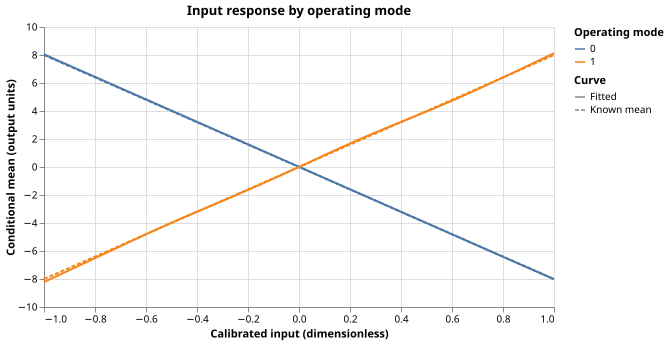

In [7]:
grid = pl.DataFrame({"x": np.tile(np.linspace(-1, 1, 100), 2),
                     "mode": np.repeat([0, 1], 100)})
curves = grid.with_columns(
    pl.Series("Fitted", search.model.predict(grid, type="response", extrapolation="allow")),
    (8 * (2 * pl.col("mode") - 1) * pl.col("x")).alias("Known mean"),
).unpivot(on=["Fitted", "Known mean"], index=["x", "mode"],
          variable_name="curve", value_name="output")
chart = alt.Chart(curves).mark_line().encode(
    x=alt.X("x:Q", title="Calibrated input (dimensionless)"),
    y=alt.Y("output:Q", title="Conditional mean (output units)"),
    color=alt.Color("mode:N", title="Operating mode"),
    strokeDash=alt.StrokeDash("curve:N", title="Curve"),
).properties(title="Input response by operating mode", width=510, height=280)
display(chart)

The two mode curves should be compared with their corresponding known means,
including their directions and deviations near the range boundaries. These are
conditional predictions in a simulated population, with no causal interpretation.

## Extension: budget exhaustion

A one-fit budget can retain a fitted linear fallback before any validation score
has been completed. Its `score` is `None` because no validation comparison was completed. You can
use the fallback to predict, but the search has no measured error for it.

In [8]:
limited = mb.auto_policy(
    train, "y", family=mb.Gaussian(), mstop=20, budget=mb.CostBudget(fits=1),
)
print(f"Stop: {limited.stopped_early}; score: {limited.score}; fits: {limited.fits}")
new_runs = pl.DataFrame({"x": [-.5, .5, -.5, .5], "mode": [0, 0, 1, 1]})
display(new_runs.with_columns(
    pl.Series("predicted_output", search.model.predict(new_runs, type="response")),
))

Stop: fits; score: None; fits: 1


x,mode,predicted_output
f64,i64,f64
-0.5,0,4.028584
0.5,0,-4.003838
-0.5,1,-3.979404
0.5,1,3.96562


The displayed predictions use the completed automatic model. Time and memory
budgets are checked between native operations and may overshoot during a call;
fit charges use admission checks. Discovery still uses family-risk rankings,
whereas complete policy candidates use the requested metric. For API details see
[](../usage/specification_search.ipynb); for domain judgments and a live-provider
extension see [](bodyfat_modeler.ipynb).

The paired-search calculation and its evaluation boundary are derived in
[](../methodology/search_decisions.ipynb).